In [1]:
import pandas as pd
from sklearn import tree

In [5]:
data = pd.read_csv(r'weather_forecast.csv')

In [6]:
data.shape

(14, 5)

In [7]:
data.head(14)

,Outlook,Temperature,Humidity,Windy,Play
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


In [9]:
#seperate input and output
#X - features(seperate input and output)
#y - target(answer we want the model to learn)
X,y = data[['Outlook','Temperature','Humidity','Windy']],data['Play']

In [12]:
#Scikit-learn cannot already work witk text
#convert categorical values into numerical representation
one_hot_data = pd.get_dummies(data[['Outlook','Temperature','Humidity','Windy','Play']],drop_first=False)
one_hot_data_X = pd.get_dummies(X,drop_first=False)
one_hot_data_y = pd.get_dummies(y,drop_first=True)

In [16]:
one_hot_data.head(20)

,Outlook_Overcast,Outlook_Rain,Outlook_Sunny,Temperature_Cool,Temperature_Hot,Temperature_Mild,Humidity_High,Humidity_Normal,Windy_Strong,Windy_Weak,Play_No,Play_Yes
0,0,0,1,0,1,0,1,0,0,1,1,0
1,0,0,1,0,1,0,1,0,1,0,1,0
2,1,0,0,0,1,0,1,0,0,1,0,1
3,0,1,0,0,0,1,1,0,0,1,0,1
4,0,1,0,1,0,0,0,1,0,1,0,1
5,0,1,0,1,0,0,0,1,1,0,1,0
6,1,0,0,1,0,0,0,1,1,0,0,1
7,0,0,1,0,0,1,1,0,0,1,1,0
8,0,0,1,1,0,0,0,1,0,1,0,1
9,0,1,0,0,0,1,0,1,0,1,0,1


In [17]:
one_hot_data_X.head(14)

,Outlook_Overcast,Outlook_Rain,Outlook_Sunny,Temperature_Cool,Temperature_Hot,Temperature_Mild,Humidity_High,Humidity_Normal,Windy_Strong,Windy_Weak
0,0,0,1,0,1,0,1,0,0,1
1,0,0,1,0,1,0,1,0,1,0
2,1,0,0,0,1,0,1,0,0,1
3,0,1,0,0,0,1,1,0,0,1
4,0,1,0,1,0,0,0,1,0,1
5,0,1,0,1,0,0,0,1,1,0
6,1,0,0,1,0,0,0,1,1,0
7,0,0,1,0,0,1,1,0,0,1
8,0,0,1,1,0,0,0,1,0,1
9,0,1,0,0,0,1,0,1,0,1


In [14]:
one_hot_data_y.head(14)

,Yes
0,0
1,0
2,1
3,1
4,1
5,0
6,1
7,0
8,1
9,1


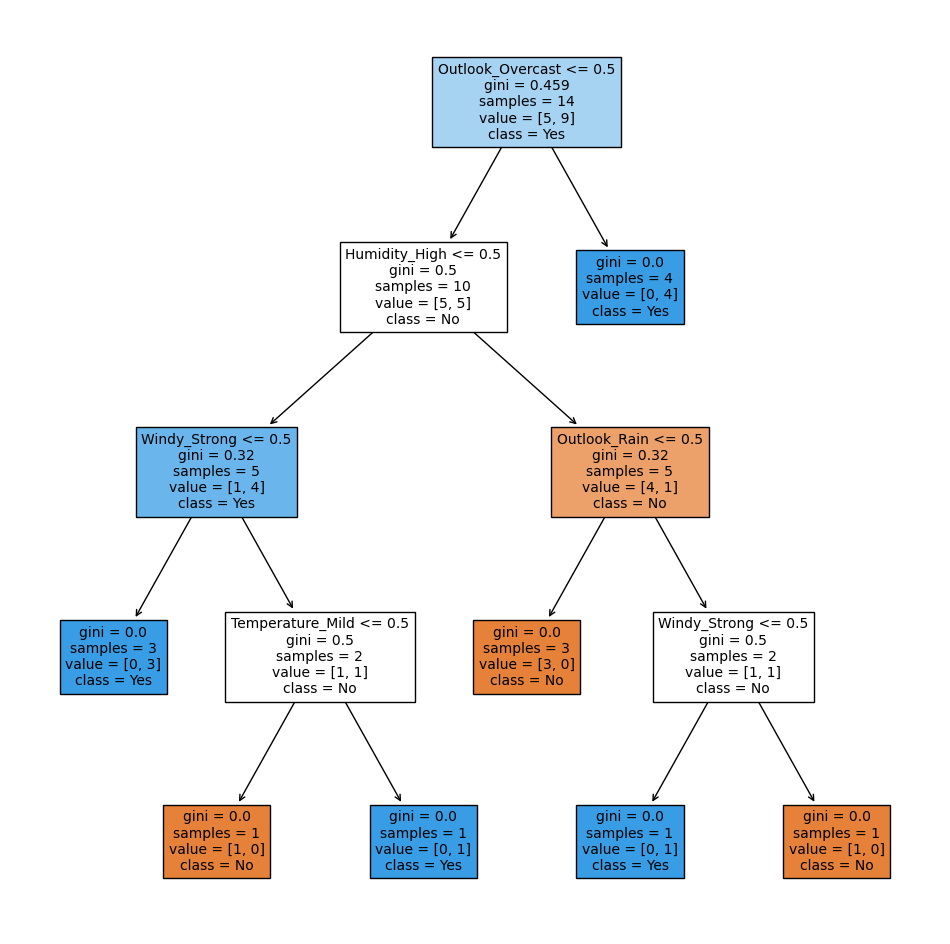

In [22]:
#Create the Decision tree

import matplotlib.pyplot as plt

#creating a decision tree classifier
classifier = tree.DecisionTreeClassifier(criterion='gini')
#Gini impurity to decide which feature should be used for

#model learns from the training data
classifier = classifier.fit(one_hot_data_X,one_hot_data_y)
plt.figure(figsize=(12,12))
tree.plot_tree(classifier,filled=True,feature_names=one_hot_data_X.columns,class_names=['No','Yes'],fontsize=10)
plt.show()

#classifier - The tarined decision tree that we want to

#Gini = 0 -> perfectly pure node
#value = [5,9] - 5 ->No,9 -> Yes
#class = Yes majority class at this node is Yes

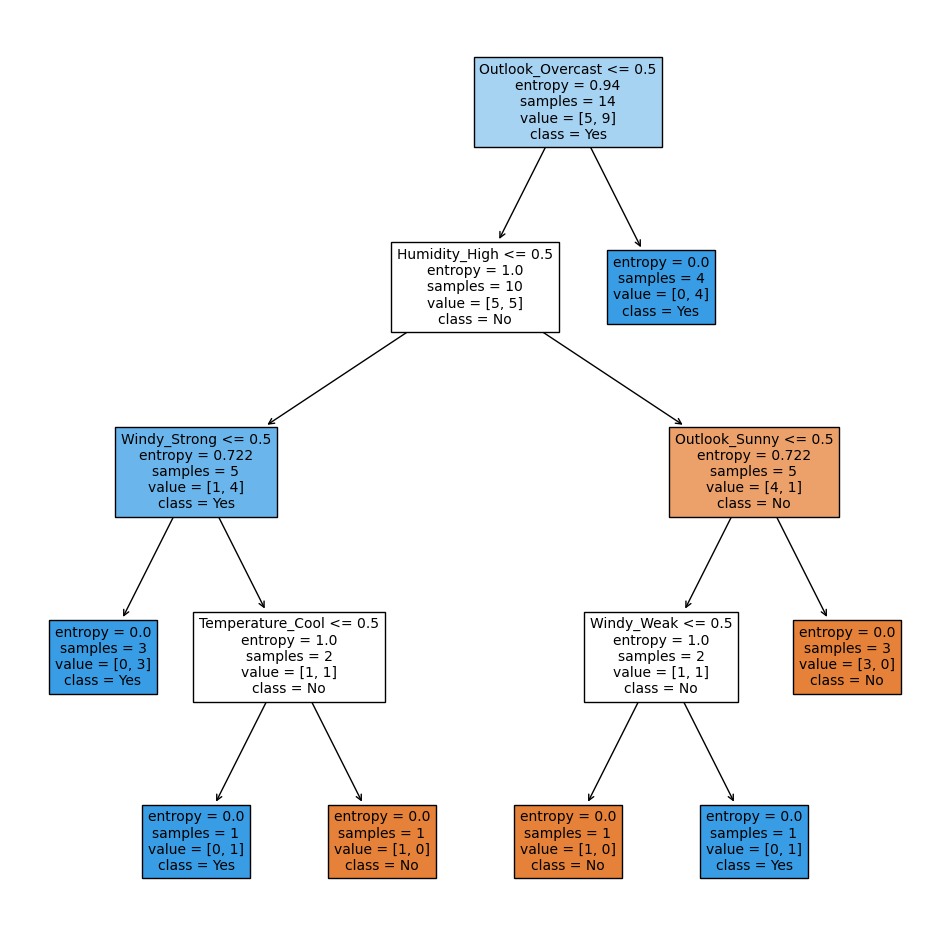

In [23]:
#Create the Decision tree

import matplotlib.pyplot as plt

#creating a decision tree classifier
classifier = tree.DecisionTreeClassifier(criterion='entropy')
#Gini impurity to decide which feature should be used for

#model learns from the training data
classifier = classifier.fit(one_hot_data_X,one_hot_data_y)
plt.figure(figsize=(12,12))
tree.plot_tree(classifier,filled=True,feature_names=one_hot_data_X.columns,class_names=['No','Yes'],fontsize=10)
plt.show()

In [24]:
from sklearn.feature_selection import mutual_info_classif
import pandas as pd

information_gain = mutual_info_classif(
    one_hot_data_X,
    one_hot_data_y,
    random_state=42
)

ig_df = pd.DataFrame({
    'Feature': one_hot_data_X.columns,
    'Information Gain': information_gain
})

ig_df = ig_df.sort_values(
    by='Information Gain',
    ascending=False
)

print(ig_df)

            Feature  Information Gain
6     Humidity_High          0.390395
7   Humidity_Normal          0.164204
0  Outlook_Overcast          0.116273
3  Temperature_Cool          0.083195
9        Windy_Weak          0.028910
2     Outlook_Sunny          0.004737
1      Outlook_Rain          0.000000
4   Temperature_Hot          0.000000
5  Temperature_Mild          0.000000
8      Windy_Strong          0.000000


C:\ProgramData\Anaconda3\lib\site-packages\sklearn\utils\validation.py:993: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
